# Olist — анализ логистики

Три вопроса о сроках доставки, опозданиях и их влиянии на оценки покупателей.

**Данные:** слой Gold, таблица `fact_orders` (одна строка на заказ).

**Определения:**

| Понятие | Определение |
|---|---|
| Срок доставки | от момента покупки до доставки покупателю, в днях |
| Опоздание | дата доставки позже обещанной даты (`estimated_delivery_date`) |
| Запас до срока | обещанная дата минус дата доставки; больше нуля — привезли раньше срока |
| Оценка | последний отзыв по заказу, 1–5 |

В расчёт входят только доставленные валидные заказы с непротиворечивыми датами (96 282 заказа):
189 заказов с нарушенным порядком дат исключены (см. [словарь данных](../../docs/data_dictionary/olist.md)).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

In [2]:
DELIVERED = "is_valid_order and delivery_days is not null"

## Среднее время доставки

**Вопрос:** сколько идёт заказ, из каких этапов складывается срок и как он менялся?
**Метрики:** среднее, медиана и 90-й перцентиль срока доставки; медиана каждого этапа; срок по месяцам и штатам.

In [3]:
overall = q(f"""
    select count(*)::bigint                                                as orders,
           avg(delivery_days)                                              as mean_days,
           median(delivery_days)                                           as median_days,
           quantile_cont(delivery_days, 0.9)                               as p90_days,
           median(datediff('day', purchase_ts, estimated_delivery_date))   as promised_median_days
    from fact_orders
    where {DELIVERED}
""")
overall.T.set_axis(["значение"], axis=1).rename(index={
    "orders": "Доставленных заказов", "mean_days": "Средний срок, дней", "median_days": "Медиана, дней",
    "p90_days": "90-й перцентиль, дней", "promised_median_days": "Обещанный срок (медиана), дней"})

,значение
Доставленных заказов,"96 282,00"
"Средний срок, дней","12,57"
"Медиана, дней","10,23"
"90-й перцентиль, дней","23,11"
"Обещанный срок (медиана), дней","24,00"


In [4]:
stages = q(f"""
    select median(approval_hours) / 24                                                   as approval,
           median(datediff('minute', approved_ts, delivered_carrier_ts)) / 1440          as seller_to_carrier,
           median(datediff('minute', delivered_carrier_ts, delivered_customer_ts)) / 1440 as carrier_to_customer
    from fact_orders
    where {DELIVERED} and approved_ts is not null and delivered_carrier_ts is not null
""").T.set_axis(["медиана, дней"], axis=1)
stages.index = ["Подтверждение оплаты", "Продавец → перевозчик", "Перевозчик → покупатель"]
stages

,"медиана, дней"
Подтверждение оплаты,"0,01"
Продавец → перевозчик,"1,82"
Перевозчик → покупатель,"7,10"


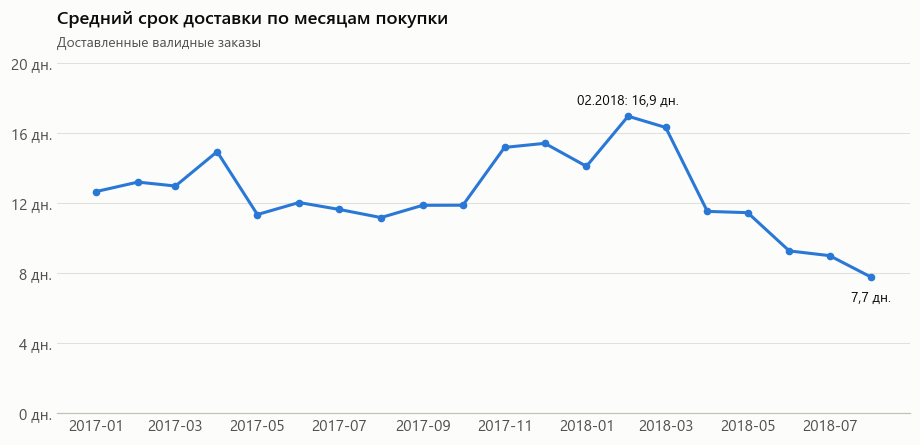

In [5]:
monthly = q(f"""
    select d.year_month,
           avg(f.delivery_days)        as mean_days,
           median(f.delivery_days)     as median_days,
           avg(f.is_late::int)         as late_rate,
           count(*)                    as orders
    from fact_orders f
    join dim_date d on d.date_key = f.purchase_date_key
    where f.is_valid_order and f.delivery_days is not null and d.is_in_analysis_window
    group by 1
    order by 1
""")
monthly["month"] = pd.to_datetime(monthly.year_month)

fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.mean_days, color=st.BLUE, marker="o", markersize=4)
ax.set_ylim(0, monthly.mean_days.max() * 1.2)
ax.yaxis.set_major_locator(plt.MultipleLocator(4))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{st.num(v)} дн."))
peak = monthly.loc[monthly.mean_days.idxmax()]
last = monthly.iloc[-1]
st.label_point(ax, peak.month, peak.mean_days, f"{peak.month:%m.%Y}: {st.num(peak.mean_days, 1)} дн.")
st.label_point(ax, last.month, last.mean_days, f"{st.num(last.mean_days, 1)} дн.", dy=-16)
st.titles(ax, "Средний срок доставки по месяцам покупки", "Доставленные валидные заказы")
st.save(fig, "olist_logistics_01_delivery_days_monthly")
plt.show()

In [6]:
states = q(f"""
    select delivery_state                as state,
           delivery_region               as region,
           count(*)                      as orders,
           avg(delivery_days)            as mean_days,
           median(delivery_days)         as median_days,
           avg(is_late::int)             as late_rate,
           avg(review_score)             as avg_score
    from fact_orders
    where {DELIVERED}
    group by 1, 2
    order by mean_days desc
""")
st.as_pct(states, ["late_rate"])

,state,region,orders,mean_days,median_days,late_rate,avg_score
0,RR,Norte,41,"29,39","25,01","12,2%","3,90"
1,AP,Norte,67,"27,19","24,35","3,0%","4,24"
2,AM,Norte,145,"26,43","25,88","2,8%","4,24"
3,AL,Nordeste,397,"24,54","22,33","21,4%","3,85"
4,PA,Norte,945,"23,78","21,08","11,2%","3,91"
5,MA,Nordeste,714,"21,61","19,21","17,5%","3,84"
6,SE,Nordeste,334,"21,55","18,03","15,3%","3,91"
7,CE,Nordeste,1278,"21,27","18,21","13,8%","3,94"
8,AC,Norte,80,"21,04","18,36","3,8%","4,09"
9,PB,Nordeste,517,"20,43","18,15","10,4%","4,08"


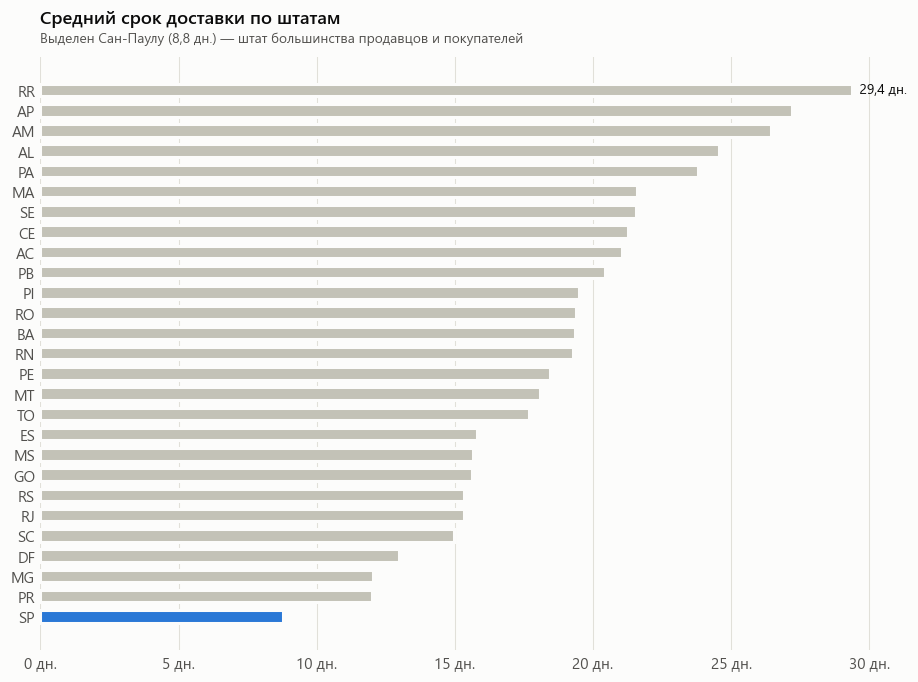

In [7]:
fig, ax = plt.subplots(figsize=(10, 7))
st.hbar(ax, states.state, states.mean_days, highlight=["SP"], color=st.BLUE,
        fmt=lambda v: f"{st.num(v, 1)} дн.")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{st.num(v)} дн."))
sp = states.loc[states.state == "SP"].iloc[0]
st.titles(ax, "Средний срок доставки по штатам", f"Выделен Сан-Паулу ({st.num(sp.mean_days, 1)} дн.) — штат большинства продавцов и покупателей")
st.save(fig, "olist_logistics_02_delivery_days_by_state")
plt.show()

**Формула**

$$D_o = \frac{t^{\mathrm{deliv}}_o - t^{\mathrm{purch}}_o}{86\,400\ \text{с}}, \qquad \bar{D} = \frac{1}{N}\sum_{o=1}^{N} D_o$$

где $t^{\mathrm{purch}}_o$ и $t^{\mathrm{deliv}}_o$ — моменты покупки и доставки заказа $o$ (разность в секундах),
$N$ — доставленные заказы с непротиворечивыми датами.

**Пример расчёта** (заказ 003a94f7…)

Покупка 03.08.2018 14:52:31, доставка 24.08.2018 00:18:38 — разница 20 суток 9 ч 26 мин 7 с:

$$D_o = 20 + \frac{33\,967}{86\,400} \approx 20{,}39 \text{ дня}$$

По всем 96 282 заказам: $\bar{D} \approx 12{,}57$, медиана $\approx 10{,}23$, $P_{90} \approx 23{,}11$ дня.

**Вывод.**
- Заказ идёт в среднем **12,6 дня**, медиана — **10,2 дня**, у 10% заказов — дольше 23 дней.
- Почти весь срок — **перевозка** (медиана 7,1 дня); продавец передаёт заказ перевозчику за ~1,8 дня,
  оплата подтверждается за минуты.
- Срок сильно зависит от расстояния: **8,8 дня в Сан-Паулу** против 20–29 дней на Севере и Северо-Востоке
  (RR, AP, AM — больше 26 дней).
- Динамика: срок рос в пиковые периоды (ноябрь 2017 – март 2018, максимум — **16,9 дня** у покупок февраля 2018)
  и затем резко сократился — до **7,7 дня** в августе 2018. Логистика заметно улучшилась к концу периода.

## Доля опоздавших заказов

**Вопрос:** как часто заказ приходит позже обещанной даты и когда опозданий больше?
**Метрики:** доля опозданий в целом, по месяцам и штатам; распределение запаса до обещанного срока.

In [8]:
late = q(f"""
    select avg(is_late::int)                      as late_rate,
           sum(is_late::int)::bigint              as late_orders,
           median(delivery_vs_estimate_days)      as median_days_before_estimate,
           avg((delivery_vs_estimate_days >= 7)::int) as share_7_plus_days_early
    from fact_orders
    where {DELIVERED}
""")
st.as_pct(late, ["late_rate", "share_7_plus_days_early"]).T.set_axis(["значение"], axis=1).rename(index={
    "late_rate": "Доля опоздавших", "late_orders": "Опоздавших заказов",
    "median_days_before_estimate": "Медиана запаса до срока, дней", "share_7_plus_days_early": "Доставлено за 7+ дней до срока"})

,значение
Доля опоздавших,"6,8%"
Опоздавших заказов,6532
"Медиана запаса до срока, дней","12,00"
Доставлено за 7+ дней до срока,"78,9%"


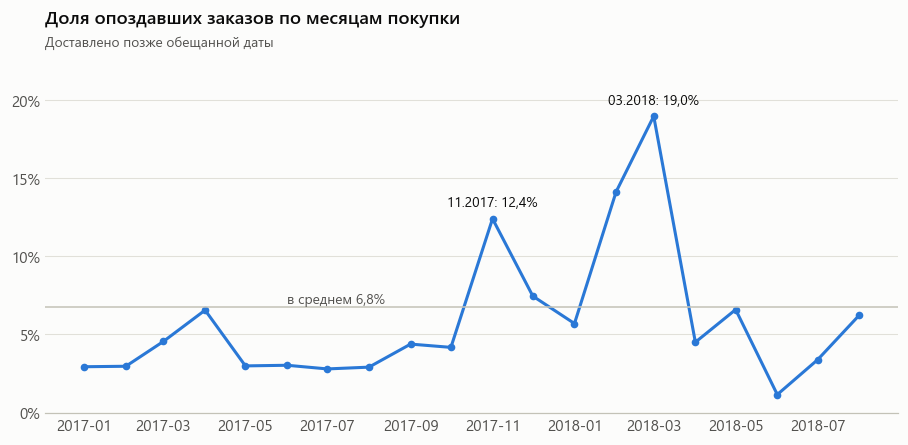

In [9]:
fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.late_rate, color=st.BLUE, marker="o", markersize=4)
avg_late = late.late_rate[0]
ax.axhline(avg_late, color=st.AXIS, linewidth=1)
ax.text(monthly.month.iloc[5], avg_late, f"в среднем {st.pct(avg_late, 1)}", va="bottom", fontsize=9, color=st.INK_2)
st.percent_axis(ax)
ax.set_ylim(0, monthly.late_rate.max() * 1.2)
for m in ["2017-11", "2018-03"]:
    r = monthly.loc[monthly.year_month == m].iloc[0]
    st.label_point(ax, r.month, r.late_rate, f"{r.month:%m.%Y}: {st.pct(r.late_rate, 1)}")
st.titles(ax, "Доля опоздавших заказов по месяцам покупки", "Доставлено позже обещанной даты")
st.save(fig, "olist_logistics_03_late_rate_monthly")
plt.show()

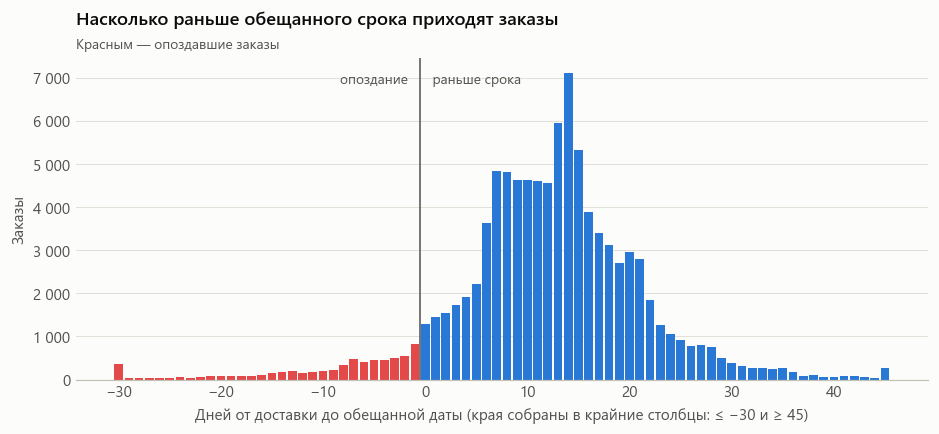

In [10]:
early = q(f"""
    select least(greatest(delivery_vs_estimate_days, -30), 45) as days_before_estimate, count(*) as orders
    from fact_orders
    where {DELIVERED}
    group by 1
    order by 1
""")
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [st.RED if d < 0 else st.BLUE for d in early.days_before_estimate]
ax.bar(early.days_before_estimate, early.orders, width=0.85, color=colors, linewidth=0)
ax.axvline(-0.5, color=st.INK_2, linewidth=1)
ax.text(-1, ax.get_ylim()[1] * 0.95, "опоздание  ", ha="right", va="top", fontsize=9, color=st.INK_2)
ax.text(0, ax.get_ylim()[1] * 0.95, "  раньше срока", ha="left", va="top", fontsize=9, color=st.INK_2)
st.count_axis(ax)
ax.set_xlabel("Дней от доставки до обещанной даты (края собраны в крайние столбцы: ≤ −30 и ≥ 45)")
ax.set_ylabel("Заказы")
st.titles(ax, "Насколько раньше обещанного срока приходят заказы", "Красным — опоздавшие заказы")
st.save(fig, "olist_logistics_04_days_before_estimate")
plt.show()

In [11]:
worst = states.sort_values("late_rate", ascending=False)
st.as_pct(worst[["state", "region", "orders", "late_rate", "mean_days"]].head(8), ["late_rate"])

,state,region,orders,late_rate,mean_days
3,AL,Nordeste,397,"21,4%","24,54"
5,MA,Nordeste,714,"17,5%","21,61"
6,SE,Nordeste,334,"15,3%","21,55"
10,PI,Nordeste,473,"14,0%","19,51"
7,CE,Nordeste,1278,"13,8%","21,27"
0,RR,Norte,41,"12,2%","29,39"
12,BA,Nordeste,3252,"12,1%","19,34"
21,RJ,Sudeste,12330,"12,1%","15,32"


**Формула**

$$\delta_o = d^{\mathrm{est}}_o - d^{\mathrm{deliv}}_o, \qquad L_o = \mathbb{1}\left[\, d^{\mathrm{deliv}}_o > d^{\mathrm{est}}_o \,\right], \qquad \text{доля опозданий} = \frac{1}{N}\sum_{o=1}^{N} L_o$$

где $d^{\mathrm{est}}_o$ — обещанная дата, $d^{\mathrm{deliv}}_o$ — дата доставки, $\delta_o$ — запас до срока
в днях (меньше нуля — опоздание), $\mathbb{1}[\cdot]$ — индикатор (1, если условие выполнено).

**Пример расчёта**

Тот же заказ 003a94f7…: обещан 15.08.2018, доставлен 24.08.2018:

$$\delta_o = 15 - 24 = -9, \qquad L_o = 1$$

По всем заказам:

$$\text{доля опозданий} = \frac{6\,532}{96\,282} \approx 0{,}0678$$

**Вывод.**
- **6,8% заказов опаздывают** (6,5 тыс. заказов). При этом типичный заказ приходит **на 12 дней раньше
  обещанного**: Olist закладывает в обещанный срок большой запас (медиана обещания — 24 дня при фактических 10).
- Опоздания сосредоточены во времени: **ноябрь 2017 (12,4%)** — Чёрная пятница — и **февраль–март 2018
  (14–19%)**, когда срок доставки был максимальным. В остальные месяцы — 1–7%.
- По штатам больше всего опозданий на Северо-Востоке: **AL (21%), MA (18%), SE (15%), PI и CE (14%)**.
  Среди крупных штатов выделяется **Рио-де-Жанейро — 12%** при сроке 15 дней: из-за большого объёма это
  самый массовый источник опозданий. А в дальних штатах Севера AP, AM, AC, RO доставка идёт 19–27 дней,
  но опаздывает лишь ~3% заказов — обещанный срок там заложен с запасом.
- Значит, опоздание — это не только долгая доставка, но и **неточное обещание**: в некоторых регионах
  обещанный срок занижен относительно реальной логистики.

## Связь оценки и времени доставки

**Вопрос:** насколько срок доставки и опоздание влияют на оценку заказа?
**Метрики:** средняя оценка и доля негативных отзывов (1–2) по сроку доставки и по запасу до обещанной даты.

In [12]:
by_late = q(f"""
    select case when is_late then 'опоздал' else 'вовремя' end as delivery,
           count(*)                            as orders,
           avg(review_score)                   as avg_score,
           avg((review_score <= 2)::int)       as negative_share,
           avg((review_score = 5)::int)        as five_share
    from fact_orders
    where {DELIVERED} and review_score is not null
    group by 1
""")
st.as_pct(by_late, ["negative_share", "five_share"])

,delivery,orders,avg_score,negative_share,five_share
0,вовремя,89258,"4,29","9,3%","62,3%"
1,опоздал,6379,"2,27","62,4%","16,5%"


In [13]:
by_days = q(f"""
    select case when delivery_days <= 7  then '0–7'
                when delivery_days <= 14 then '8–14'
                when delivery_days <= 21 then '15–21'
                when delivery_days <= 30 then '22–30'
                else 'больше 30' end            as delivery_bucket,
           min(delivery_days)                   as sort_key,
           count(*)                             as orders,
           avg(review_score)                    as avg_score,
           avg((review_score <= 2)::int)        as negative_share
    from fact_orders
    where {DELIVERED} and review_score is not null
    group by 1
    order by sort_key
""")
st.as_pct(by_days.drop(columns="sort_key"), ["negative_share"])

,delivery_bucket,orders,avg_score,negative_share
0,0–7,25827,"4,42","7,4%"
1,8–14,39935,"4,31","9,0%"
2,15–21,17564,"4,14","11,7%"
3,22–30,7882,"3,61","24,3%"
4,больше 30,4429,"2,25","63,0%"


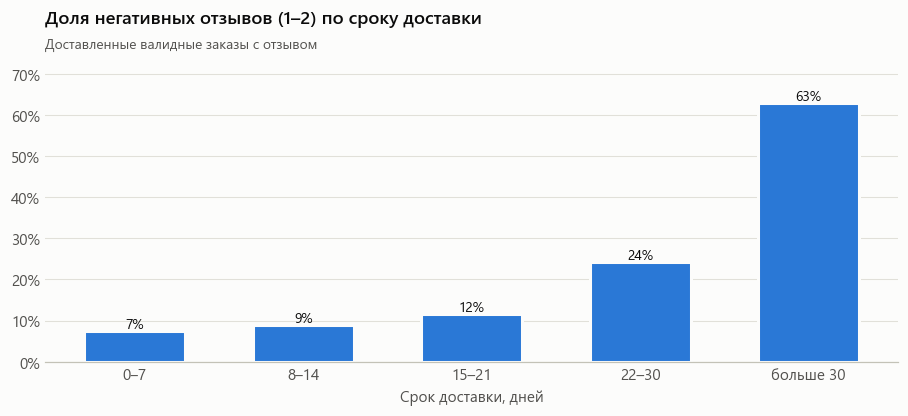

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_days.delivery_bucket, by_days.negative_share, color=st.BLUE, width=0.6, edgecolor=st.SURFACE, linewidth=2)
for i, r in by_days.iterrows():
    ax.text(i, r.negative_share, st.pct(r.negative_share), ha="center", va="bottom", fontsize=9, color=st.INK)
st.percent_axis(ax)
ax.set_ylim(0, by_days.negative_share.max() * 1.18)
ax.set_xlabel("Срок доставки, дней")
st.titles(ax, "Доля негативных отзывов (1–2) по сроку доставки", "Доставленные валидные заказы с отзывом")
st.save(fig, "olist_logistics_05_negative_by_delivery_days")
plt.show()

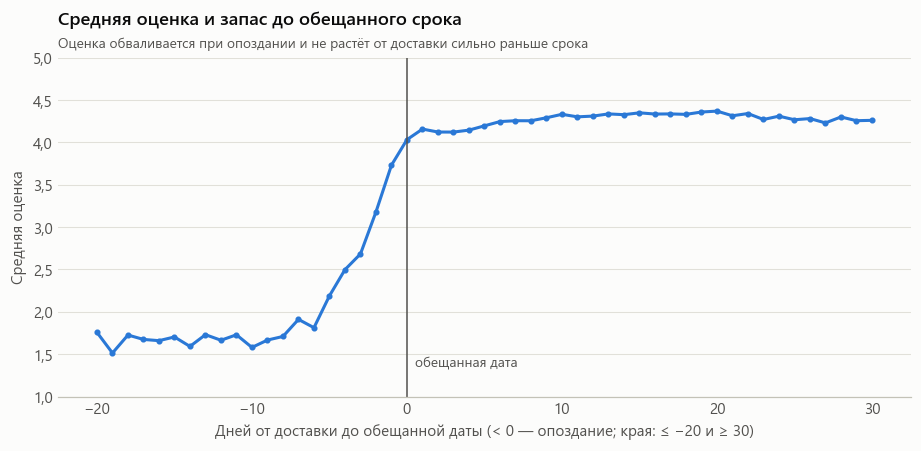

In [15]:
score_curve = q(f"""
    select least(greatest(delivery_vs_estimate_days, -20), 30) as days_before_estimate,
           count(*)                                            as orders,
           avg(review_score)                                   as avg_score
    from fact_orders
    where {DELIVERED} and review_score is not null
    group by 1
    order by 1
""")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(score_curve.days_before_estimate, score_curve.avg_score, color=st.BLUE, marker="o", markersize=3)
ax.axvline(0, color=st.INK_2, linewidth=1)
ax.text(0.5, 1.35, "обещанная дата", fontsize=9, color=st.INK_2)
ax.set_ylim(1, 5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.num(v, 1)))
ax.set_xlabel("Дней от доставки до обещанной даты (< 0 — опоздание; края: ≤ −20 и ≥ 30)")
ax.set_ylabel("Средняя оценка")
st.titles(ax, "Средняя оценка и запас до обещанного срока", "Оценка обваливается при опоздании и не растёт от доставки сильно раньше срока")
st.save(fig, "olist_logistics_06_score_vs_estimate")
plt.show()

In [16]:
corr = q(f"""
    select corr(delivery_days, review_score)               as corr_delivery_days,
           corr(delivery_vs_estimate_days, review_score)   as corr_days_before_estimate
    from fact_orders
    where {DELIVERED} and review_score is not null
""")
corr

,corr_delivery_days,corr_days_before_estimate
0,"-0,33","0,27"


**Формула**

$$\Delta \bar{s} = \bar{s}_{\text{опозд}} - \bar{s}_{\text{вовремя}}, \qquad \mathrm{RR} = \frac{p^{\text{нег}}_{\text{опозд}}}{p^{\text{нег}}_{\text{вовремя}}}$$

где $\bar{s}$ — средняя оценка группы, $p^{\text{нег}}$ — доля оценок 1–2 в группе, $\mathrm{RR}$ — во сколько раз
опоздание повышает риск негативного отзыва.

**Пример расчёта**

$$\Delta \bar{s} = 2{,}27 - 4{,}29 = -2{,}02$$

$$p^{\text{нег}}_{\text{опозд}} = \frac{3\,982}{6\,379} \approx 0{,}624, \qquad p^{\text{нег}}_{\text{вовремя}} = \frac{8\,266}{89\,258} \approx 0{,}093, \qquad \mathrm{RR} \approx 6{,}7$$

Корреляция Пирсона оценки со сроком доставки $r \approx -0{,}33$, с запасом до срока $r \approx 0{,}27$.

**Вывод.**
- **Опоздание — самый сильный фактор оценки:** опоздавшие заказы получают в среднем **2,3 балла** против **4,3**
  у доставленных вовремя. Негативных отзывов — **62% против 9%**, пятёрок — 17% против 62%.
- Долгая доставка сама по себе вредит меньше: до 21 дня доля негатива растёт плавно (7% → 12%),
  после 30 дней — **63%**.
- Ключевой график — оценка по запасу до срока: пока заказ приходит **до обещанной даты, оценка стабильна (~4,2–4,4)
  независимо от того, на сколько дней раньше**. Уже за 1–2 дня опоздания она падает до 3,2–3,7, после недели —
  до ~1,7.
- Практический вывод: покупатели оценивают **выполнение обещания**, а не абсолютную скорость. Самый дешёвый
  способ поднять оценки — точнее обещать срок в регионах с частыми опозданиями (AL, MA, SE, CE, RJ) и
  предупреждать о задержке в пиковые периоды. Ускорять и без того ранние доставки почти бесполезно для оценки.

## Итоги

| Вопрос | Ответ |
|---|---|
| Срок доставки | 12,6 дня в среднем (медиана 10,2); почти весь срок — перевозка; SP 8,8 дня, Север 20–29; к августу 2018 — 7,7 дня |
| Опоздания | 6,8%; пики — Чёрная пятница и февраль–март 2018 (до 19%); больше всего в AL, MA, SE и (по объёму) RJ |
| Оценка и доставка | опоздание: 2,3 против 4,3 балла, 62% негатива; доставка раньше срока оценку не повышает |